In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# -------------------------------------------------------
# 1. Load Iris Dataset
# -------------------------------------------------------

df = pd.read_csv("Iris.csv")

print("First 5 rows of dataset:")
print(df.head())

print("\nDataset Columns:")
print(df.columns)

First 5 rows of dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Columns:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')


In [4]:
# -------------------------------------------------------
# 2. Remove ID column if present
# -------------------------------------------------------

if "Id" in df.columns:
    df = df.drop("Id", axis=1)

In [5]:
# -------------------------------------------------------
# 3. Separate Features and Target
# -------------------------------------------------------

# Assuming the last column contains the species/class
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("\nFeatures:")
print(X.columns)

print("\nClasses:")
print(y.unique())


Features:
Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'], dtype='str')

Classes:
<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


In [6]:
# -------------------------------------------------------
# 4. Split Dataset
# -------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
# -------------------------------------------------------
# 5. Create ID3 Decision Tree
# -------------------------------------------------------

# ID3 uses Entropy and Information Gain
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)


# -------------------------------------------------------
# 6. Prediction on Test Dataset
# -------------------------------------------------------

y_pred = model.predict(X_test)

In [8]:
# -------------------------------------------------------
# 7. Model Evaluation
# -------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9333333333333333

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



In [9]:
# -------------------------------------------------------
# 8. Print Decision Tree as IF-ELSE Rules
# -------------------------------------------------------

rules = export_text(
    model,
    feature_names=list(X.columns)
)

print("\nDecision Tree IF-ELSE Rules:\n")
print(rules)


Decision Tree IF-ELSE Rules:

|--- PetalLengthCm <= 2.45
|   |--- class: Iris-setosa
|--- PetalLengthCm >  2.45
|   |--- PetalWidthCm <= 1.65
|   |   |--- PetalLengthCm <= 4.95
|   |   |   |--- class: Iris-versicolor
|   |   |--- PetalLengthCm >  4.95
|   |   |   |--- SepalLengthCm <= 6.15
|   |   |   |   |--- SepalWidthCm <= 2.45
|   |   |   |   |   |--- class: Iris-virginica
|   |   |   |   |--- SepalWidthCm >  2.45
|   |   |   |   |   |--- class: Iris-versicolor
|   |   |   |--- SepalLengthCm >  6.15
|   |   |   |   |--- class: Iris-virginica
|   |--- PetalWidthCm >  1.65
|   |   |--- PetalLengthCm <= 4.85
|   |   |   |--- SepalWidthCm <= 3.00
|   |   |   |   |--- class: Iris-virginica
|   |   |   |--- SepalWidthCm >  3.00
|   |   |   |   |--- class: Iris-versicolor
|   |   |--- PetalLengthCm >  4.85
|   |   |   |--- class: Iris-virginica



In [10]:
# -------------------------------------------------------
# 9. Predict a New Sample
# -------------------------------------------------------

# New sample:
# Sepal Length = 5.1
# Sepal Width  = 3.5
# Petal Length = 1.4
# Petal Width  = 0.2

new_sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = model.predict(new_sample)

print("\nNew Sample:")
print(new_sample)

print("\nPredicted Species:", prediction[0])



New Sample:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2

Predicted Species: Iris-setosa


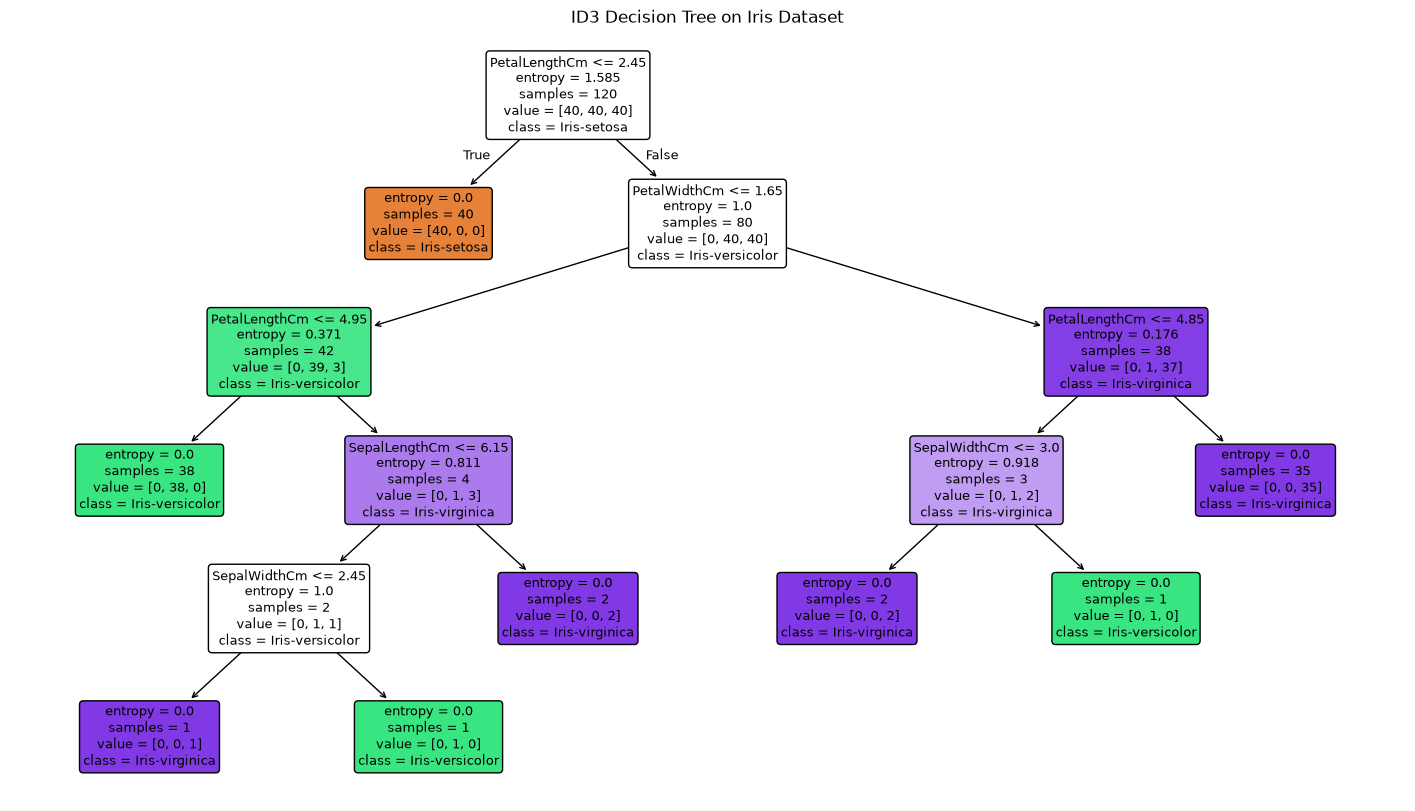

In [11]:
# -------------------------------------------------------
# 10. Plot Decision Tree
# -------------------------------------------------------

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("ID3 Decision Tree on Iris Dataset")

plt.show()